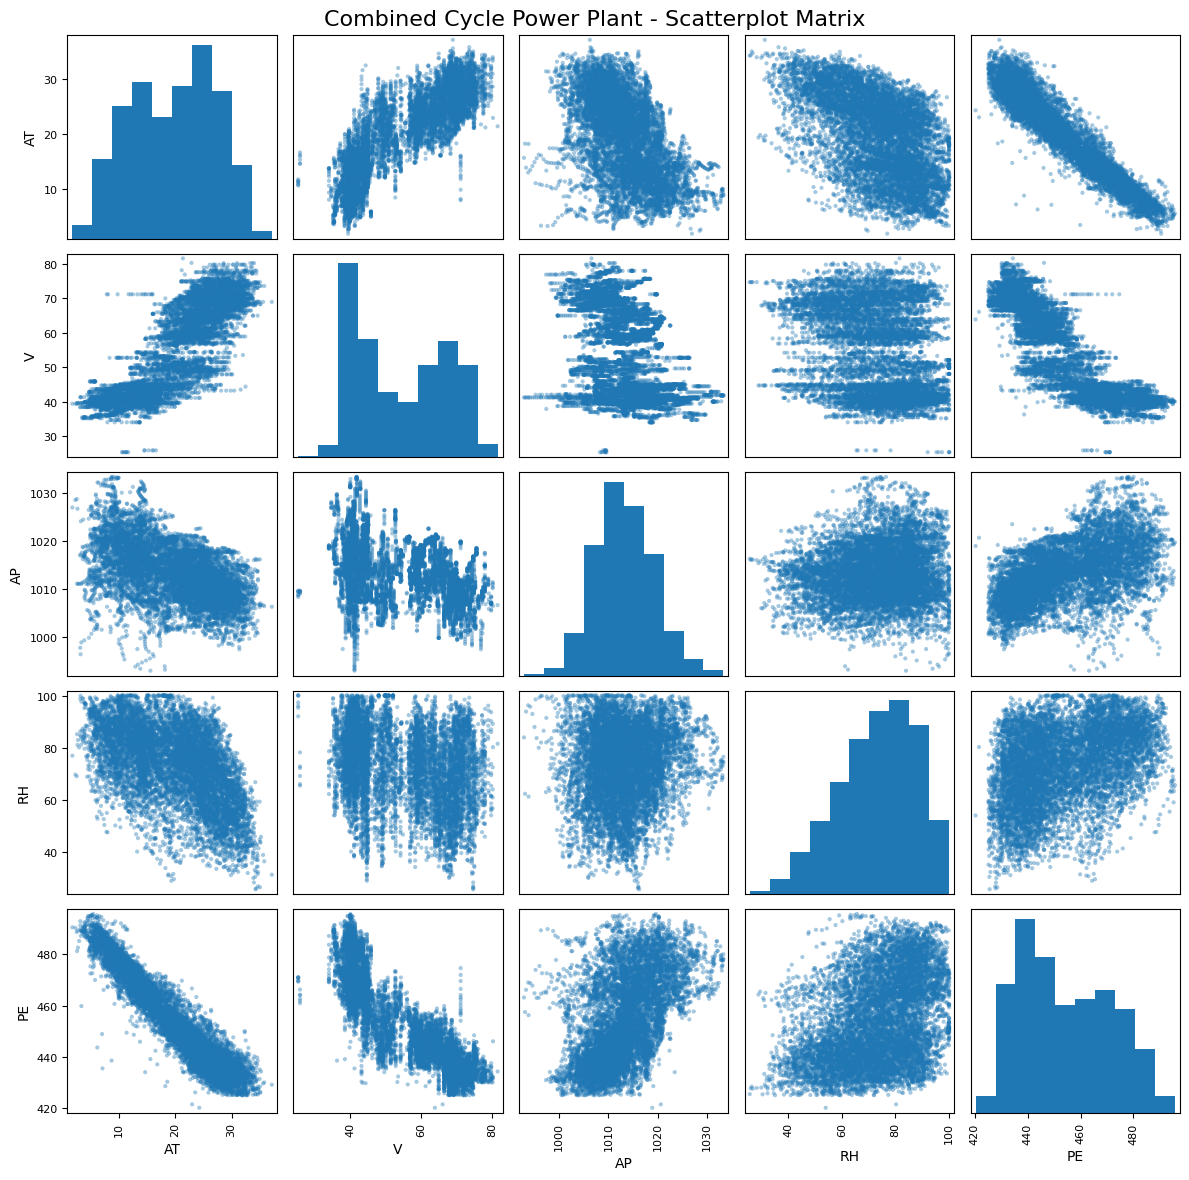

        AT       V      AP      RH      PE
AT  1.0000  0.8441 -0.5075 -0.5425 -0.9481
V   0.8441  1.0000 -0.4135 -0.3122 -0.8698
AP -0.5075 -0.4135  1.0000  0.0996  0.5184
RH -0.5425 -0.3122  0.0996  1.0000  0.3898
PE -0.9481 -0.8698  0.5184  0.3898  1.0000

X shape: torch.Size([9568, 4])
y shape: torch.Size([9568, 1])
Mean of standardized features: tensor([-1.8343e-16, -1.9160e-16,  5.4746e-15, -3.3270e-16],
       dtype=torch.float64)
Standard deviation: tensor([1.0000, 1.0000, 1.0000, 1.0000], dtype=torch.float64)


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from pandas.plotting import scatter_matrix

df = pd.read_csv("Folds5x2_pp.csv")

# print(df.head())
# print(df.shape)
# print(df.columns)

# Scatterplot Matrix
scatter_matrix(df, figsize=(12, 12), diagonal='hist', alpha=0.4)

plt.suptitle("Combined Cycle Power Plant - Scatterplot Matrix", fontsize=16)
plt.tight_layout()
plt.show()


# Correlation Matrix
correlationMatrix = df.corr()

print(correlationMatrix.round(4))


# Separate features and target
X = df[['AT', 'V', 'AP', 'RH']].values
y = df['PE'].values

# Calculate mean and standard deviation
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)

# Standardize features
X_scaled = (X - X_mean) / X_std

# Convert to PyTorch tensors
X_tensor = torch.tensor(X_scaled, dtype=torch.float64)
y_tensor = torch.tensor(y, dtype=torch.float64).reshape(-1, 1)

print("\nX shape:", X_tensor.shape)
print("y shape:", y_tensor.shape)
print("Mean of standardized features:", X_tensor.mean(dim=0))
print("Standard deviation:", X_tensor.std(dim=0, correction=0))



In [21]:
class CauchyRegression:
    def __init__(self, nFeatures, c=1.0):
        self.c = c

        # Initialize coefficients and intercept
        self.weights = torch.zeros((nFeatures, 1), dtype=torch.float64, requires_grad=True)
        self.bias = torch.tensor([y_tensor.mean().item()], dtype=torch.float64, requires_grad=True)

        self.lossHistory = []

    def forward(self, X):
        return X @ self.weights + self.bias

    def cauchyLoss(self, yPred, yTrue):
        error = yTrue - yPred
        loss = (self.c**2 / 2) * torch.log1p((error / self.c)**2)
        return torch.mean(loss)

    def fit(self, X, y, learningRate=0.01, epochs=5000):
        optimizer = torch.optim.SGD([self.weights, self.bias], lr=learningRate)

        for epoch in range(epochs):
            optimizer.zero_grad()

            yPred = self.forward(X)
            loss = self.cauchyLoss(yPred, y)

            loss.backward()
            optimizer.step()

            self.lossHistory.append(loss.item())

            if (epoch + 1) % 500 == 0:
                print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.6f}")

    def predict(self, X):
        with torch.no_grad():
            return self.forward(X)

Epoch 500/5000, Loss: 2.428447
Epoch 1000/5000, Loss: 2.383777
Epoch 1500/5000, Loss: 2.334583
Epoch 2000/5000, Loss: 2.279838
Epoch 2500/5000, Loss: 2.218757
Epoch 3000/5000, Loss: 2.149460
Epoch 3500/5000, Loss: 2.069775
Epoch 4000/5000, Loss: 1.979097
Epoch 4500/5000, Loss: 1.877175
Epoch 5000/5000, Loss: 1.771075

Final Loss: 1.7708673756615676


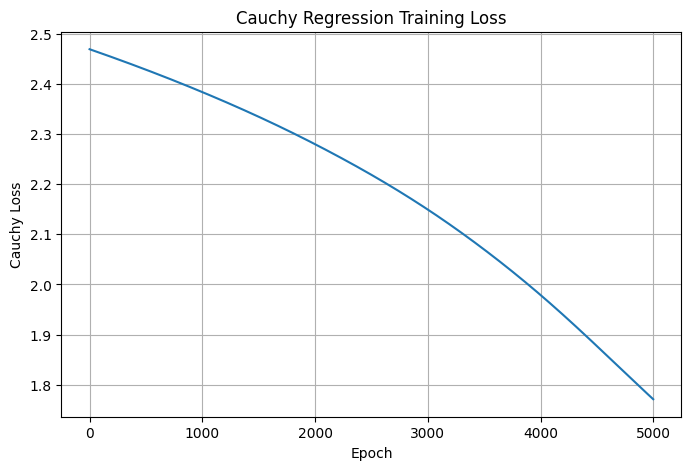

----- Cauchy Regression Coefficients -----
Intercept (w0): 111.575098
AT: -0.482098
V: -0.296432
AP: 0.356099
RH: 0.092405

Final Cauchy Loss: 1.770867


In [22]:
# Create the model
model = CauchyRegression(nFeatures=4, c=1.0)

# Train the model
model.fit(X_tensor, y_tensor, learningRate=0.01, epochs=5000)

# Final training loss
with torch.no_grad():
    finalLoss = model.cauchyLoss(model.predict(X_tensor), y_tensor).item()

print("\nFinal Loss:", finalLoss)

# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(model.lossHistory)
plt.xlabel("Epoch")
plt.ylabel("Cauchy Loss")
plt.title("Cauchy Regression Training Loss")
plt.grid(True)
plt.show()


# Get trained coefficients
scaledWeights = model.weights.detach().numpy().flatten()
scaledBias = model.bias.detach().item()

# Convert coefficients to original feature units
originalWeights = scaledWeights / X_std
originalBias = scaledBias - np.sum(originalWeights * X_mean)

# Print coefficients
print("----- Cauchy Regression Coefficients -----")
print(f"Intercept (w0): {originalBias:.6f}")

for feature, weight in zip(['AT', 'V', 'AP', 'RH'], originalWeights):
    print(f"{feature}: {weight:.6f}")

print(f"\nFinal Cauchy Loss: {finalLoss:.6f}")



In [23]:
# Problem 5.3 - Regression Coefficients

scaledWeights = model.weights.detach().numpy().flatten()
scaledBias = model.bias.detach().item()

# Convert back to original units
originalWeights = scaledWeights / X_std
originalBias = scaledBias - np.sum(originalWeights * X_mean)

print("----- Cauchy Regression Coefficients -----")
print(f"w0 (Intercept): {originalBias:.6f}")
print(f"w1 (AT):        {originalWeights[0]:.6f}")
print(f"w2 (V):         {originalWeights[1]:.6f}")
print(f"w3 (AP):        {originalWeights[2]:.6f}")
print(f"w4 (RH):        {originalWeights[3]:.6f}")

----- Cauchy Regression Coefficients -----
w0 (Intercept): 111.575098
w1 (AT):        -0.482098
w2 (V):         -0.296432
w3 (AP):        0.356099
w4 (RH):        0.092405


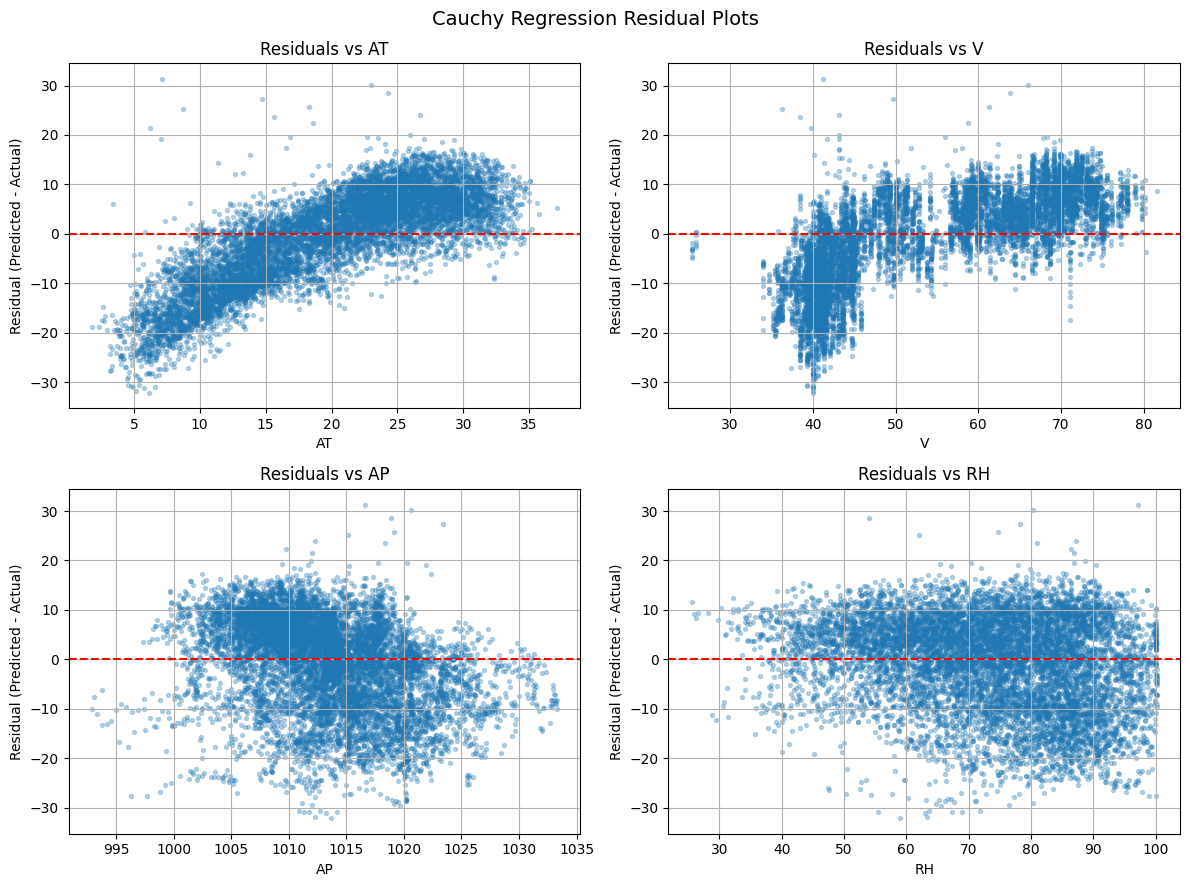

Mean Residual: -0.767548
Residual Standard Deviation: 9.344824


In [24]:

# Problem 5.6 - Residual Plots

# Generate predictions
yPred = model.predict(X_tensor).detach().numpy().flatten()
yTrue = y_tensor.numpy().flatten()

# Calculate residuals (Predicted - Actual)
residuals = yPred - yTrue

features = ['AT', 'V', 'AP', 'RH']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, feature in enumerate(features):
    ax = axes.flat[i]

    ax.scatter(df[feature], residuals, alpha=0.3, s=8)
    ax.axhline(y=0, color='red', linestyle='--')

    ax.set_xlabel(feature)
    ax.set_ylabel("Residual (Predicted - Actual)")
    ax.set_title(f"Residuals vs {feature}")
    ax.grid(True)

plt.suptitle("Cauchy Regression Residual Plots", fontsize=14)
plt.tight_layout()
plt.show()

print(f"Mean Residual: {np.mean(residuals):.6f}")
print(f"Residual Standard Deviation: {np.std(residuals):.6f}")

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Load dataset
bank = pd.read_csv("bank-full.csv", sep=";")

# print(bank.head())
# print(bank.shape)
# print(bank.columns)

# # Check class distribution
# print("\nClass Distribution:")
# print(bank["y"].value_counts())
# print(bank["y"].value_counts(normalize=True))

# Problem 6 - Prepare Logistic Regression Data

bankFeatures = ['age', 'balance', 'campaign', 'pdays', 'previous']

# Extract features and target
bankX = bank[bankFeatures].to_numpy(dtype=np.float64)
bankY = (bank['y'] == 'yes').to_numpy(dtype=np.float64)

print("Features Shape:", bankX.shape)
print("Target Shape:", bankY.shape)

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

XTrain, XTest, yTrain, yTest = train_test_split(
    bankX,
    bankY,
    test_size=0.2,
    random_state=42,
    stratify=bankY
)

# Standardize using training data only
bankMean = XTrain.mean(axis=0)
bankStd = XTrain.std(axis=0)

bankStd[bankStd == 0] = 1

XTrain = (XTrain - bankMean) / bankStd
XTest = (XTest - bankMean) / bankStd

# Convert to PyTorch tensors
bankXTrain = torch.tensor(XTrain, dtype=torch.float64)
bankXTest = torch.tensor(XTest, dtype=torch.float64)

bankYTrain = torch.tensor(yTrain, dtype=torch.float64).reshape(-1, 1)
bankYTest = torch.tensor(yTest, dtype=torch.float64).reshape(-1, 1)

print("\nTraining Samples:", len(bankXTrain))
print("Testing Samples:", len(bankXTest))
print("Number of Features:", bankXTrain.shape[1])

Features Shape: (45211, 5)
Target Shape: (45211,)

Training Samples: 36168
Testing Samples: 9043
Number of Features: 5


In [26]:
# Problem 6 - Logistic Regression Class

class LogisticRegression:
    def __init__(self, nFeatures):
        self.weights = torch.zeros(
            (nFeatures, 1),
            dtype=torch.float64,
            requires_grad=True
        )

        self.bias = torch.zeros(
            (1,),
            dtype=torch.float64,
            requires_grad=True
        )

        self.lossHistory = []

    def forward(self, X):
        z = X @ self.weights + self.bias
        return torch.sigmoid(z)

    def crossEntropyLoss(self, yPred, yTrue):
        # Prevent log(0)
        epsilon = 1e-12
        yPred = torch.clamp(yPred, epsilon, 1 - epsilon)

        loss = -(
            yTrue * torch.log(yPred)
            + (1 - yTrue) * torch.log(1 - yPred)
        )

        return torch.mean(loss)

    def fit(self, X, y, learningRate=0.01, epochs=100):
        optimizer = torch.optim.SGD(
            [self.weights, self.bias],
            lr=learningRate
        )

        dataset = torch.utils.data.TensorDataset(X, y)
        loader = torch.utils.data.DataLoader(
            dataset,
            batch_size=128,
            shuffle=True
        )

        for epoch in range(epochs):
            totalLoss = 0

            for batchX, batchY in loader:
                optimizer.zero_grad()

                yPred = self.forward(batchX)
                loss = self.crossEntropyLoss(yPred, batchY)

                loss.backward()
                optimizer.step()

                totalLoss += loss.item() * len(batchX)

            averageLoss = totalLoss / len(X)
            self.lossHistory.append(averageLoss)

            if (epoch + 1) % 10 == 0:
                print(
                    f"Epoch {epoch+1}/{epochs}, "
                    f"Loss: {averageLoss:.6f}"
                )

    def predict(self, X, threshold=0.5):
        with torch.no_grad():
            probabilities = self.forward(X)
            return (probabilities >= threshold).int()


Epoch 10/100, Loss: 0.351795
Epoch 20/100, Loss: 0.351004
Epoch 30/100, Loss: 0.350941
Epoch 40/100, Loss: 0.350934
Epoch 50/100, Loss: 0.350930
Epoch 60/100, Loss: 0.350930
Epoch 70/100, Loss: 0.350931
Epoch 80/100, Loss: 0.350929
Epoch 90/100, Loss: 0.350930
Epoch 100/100, Loss: 0.350929


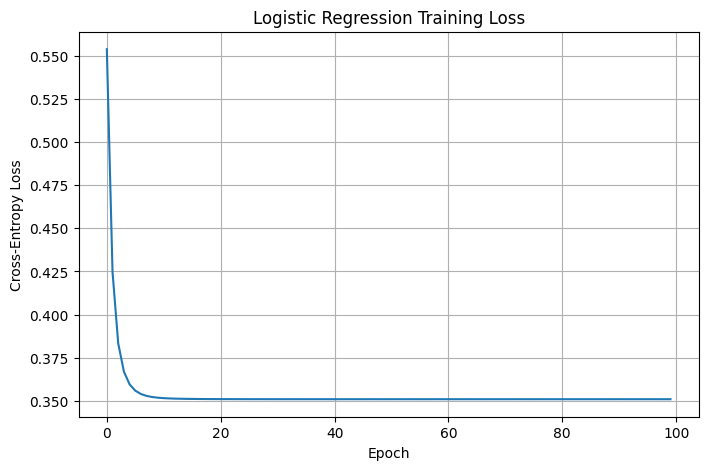

In [27]:

# Create and train logistic regression model

logitModel = LogisticRegression(nFeatures=5)

logitModel.fit(
    bankXTrain,
    bankYTrain,
    learningRate=0.01,
    epochs=100
)

# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(logitModel.lossHistory)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Logistic Regression Training Loss")
plt.grid(True)
plt.show()

----- Logistic Regression Evaluation -----
Accuracy:  0.8826
Precision: 0.2500
Recall:    0.0019
F1 Score:  0.0038

Classification Report:
              precision    recall  f1-score   support

          No       0.88      1.00      0.94      7985
         Yes       0.25      0.00      0.00      1058

    accuracy                           0.88      9043
   macro avg       0.57      0.50      0.47      9043
weighted avg       0.81      0.88      0.83      9043



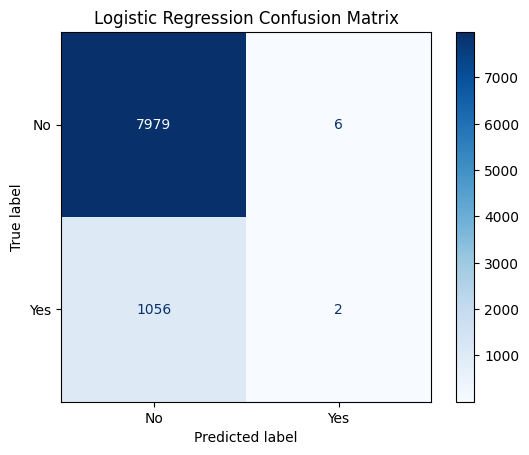

In [28]:

# Problem 6 - Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Generate test predictions
yPred = logitModel.predict(bankXTest).numpy().flatten()
yTrue = bankYTest.numpy().flatten().astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(yTrue, yPred)
precision = precision_score(yTrue, yPred, zero_division=0)
recall = recall_score(yTrue, yPred, zero_division=0)
f1 = f1_score(yTrue, yPred, zero_division=0)

print("----- Logistic Regression Evaluation -----")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(yTrue, yPred, target_names=["No", "Yes"], zero_division=0))

# Confusion Matrix
cm = confusion_matrix(yTrue, yPred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [29]:
# Compare classification thresholds

with torch.no_grad():
    probabilities = logitModel.forward(bankXTest).numpy().flatten()

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

print("Threshold    Accuracy    Precision    Recall    F1")

for threshold in thresholds:
    predictions = (probabilities >= threshold).astype(int)

    acc = accuracy_score(yTrue, predictions)
    prec = precision_score(yTrue, predictions, zero_division=0)
    rec = recall_score(yTrue, predictions, zero_division=0)
    f1 = f1_score(yTrue, predictions, zero_division=0)

    print(f"{threshold:<12.2f}{acc:<12.4f}{prec:<13.4f}{rec:<10.4f}{f1:.4f}")



Threshold    Accuracy    Precision    Recall    F1
0.50        0.8826      0.2500       0.0019    0.0038
0.40        0.8816      0.1905       0.0038    0.0074
0.30        0.8794      0.2000       0.0104    0.0198
0.20        0.8546      0.2340       0.1068    0.1467
0.10        0.3894      0.1379       0.8034    0.2354
